In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import datetime as dt
df = pd.read_csv('/content/drive/MyDrive/data-portfolio-project/online_retail_II.csv')
print(df.shape)

Mounted at /content/drive
(1067371, 8)


In [ ]:
# 1. แปลงวันที่ให้ถูกต้อง
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], format='mixed', dayfirst=True)
print(df['InvoiceDate'].min(), df['InvoiceDate'].max())

# 2. เช็ค overlap ระหว่าง C-invoice กับ Quantity ติดลบ
c_invoice = df['Invoice'].astype(str).str.startswith('C')
print("จำนวนแถว C-invoice:", c_invoice.sum())
print("จำนวนแถว Quantity ติดลบ:", (df['Quantity'] < 0).sum())
print("แถว Quantity ติดลบ ที่เป็น C-invoice:", (c_invoice & (df['Quantity'] < 0)).sum())
print("แถว Quantity ติดลบ ที่ไม่ใช่ C-invoice:", (~c_invoice & (df['Quantity'] < 0)).sum())

2009-12-01 07:45:00 2011-12-09 12:50:00
จำนวนแถว C-invoice: 19494
จำนวนแถว Quantity ติดลบ: 22950
แถว Quantity ติดลบ ที่เป็น C-invoice: 19493
แถว Quantity ติดลบ ที่ไม่ใช่ C-invoice: 3457


In [ ]:
c_invoice = df['Invoice'].astype(str).str.startswith('C')
qty_neg = df['Quantity'] < 0

print("จำนวนแถว C-invoice ทั้งหมด:", c_invoice.sum())
print("จำนวนแถว Quantity ติดลบทั้งหมด:", qty_neg.sum())
print("แถว Quantity ติดลบ ที่เป็น C-invoice:", (c_invoice & qty_neg).sum())
print("แถว Quantity ติดลบ ที่ไม่ใช่ C-invoice:", (~c_invoice & qty_neg).sum())
print("แถว C-invoice ที่ Quantity ไม่ติดลบ:", (c_invoice & ~qty_neg).sum())

จำนวนแถว C-invoice ทั้งหมด: 19494
จำนวนแถว Quantity ติดลบทั้งหมด: 22950
แถว Quantity ติดลบ ที่เป็น C-invoice: 19493
แถว Quantity ติดลบ ที่ไม่ใช่ C-invoice: 3457
แถว C-invoice ที่ Quantity ไม่ติดลบ: 1


In [ ]:
# ดูตัวอย่างแถว Quantity ติดลบ ที่ไม่ใช่ C-invoice
weird_returns = df[(df['Quantity'] < 0) & (~df['Invoice'].astype(str).str.startswith('C'))]
weird_returns.head(15)

# เช็คว่า StockCode ของกลุ่มนี้มีอะไรผิดปกติไหม (เช่น เป็นรหัสพิเศษ ไม่ใช่สินค้าจริง)
weird_returns['StockCode'].value_counts().head(10)

# เช็คว่า Customer ID หายไปเยอะไหมในกลุ่มนี้
weird_returns['Customer ID'].isna().sum()

np.int64(3457)

In [ ]:
# ===== DATA CLEANING =====
print("ขนาดข้อมูลก่อน clean:", df.shape)

# 1. แปลงวันที่ให้ถูกต้อง (format ปนกันในไฟล์ จึงต้องใช้ mixed)
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], format='mixed', dayfirst=True)

# 2. ตัดแถวที่ไม่มี Customer ID ทิ้ง - จำเป็นเพราะทำ segmentation ต่อไม่ได้ถ้าไม่รู้ว่าใครซื้อ
df_clean = df.dropna(subset=['Customer ID']).copy()
print("หลังตัด missing Customer ID:", df_clean.shape)

# 3. ตัดแถวที่เป็น cancelled order (Invoice ขึ้นต้นด้วย 'C') ทิ้ง - ไม่ใช่ยอดขายจริง
df_clean = df_clean[~df_clean['Invoice'].astype(str).str.startswith('C')]
print("หลังตัด cancelled orders:", df_clean.shape)

# 4. เช็คอีกรอบว่ายัง Quantity ติดลบเหลืออยู่ไหม (ควรจะเหลือน้อยมากหรือไม่มีเลย)
print("Quantity ติดลบที่เหลือ:", (df_clean['Quantity'] < 0).sum())

# 5. สร้างคอลัมน์ TotalPrice ไว้ใช้ต่อ (จำเป็นสำหรับ RFM analysis ขั้นถัดไป)
df_clean['TotalPrice'] = df_clean['Quantity'] * df_clean['Price']

# 6. Customer ID แปลงเป็น int จะได้ไม่มี .0 ติดท้าย
df_clean['Customer ID'] = df_clean['Customer ID'].astype(int)

print("\n===== สรุปข้อมูลหลัง clean =====")
df_clean.info()

ขนาดข้อมูลก่อน clean: (1067371, 8)
หลังตัด missing Customer ID: (824364, 8)
หลังตัด cancelled orders: (805620, 8)
Quantity ติดลบที่เหลือ: 0

===== สรุปข้อมูลหลัง clean =====
<class 'pandas.core.frame.DataFrame'>
Index: 805620 entries, 0 to 1067370
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      805620 non-null  object        
 1   StockCode    805620 non-null  object        
 2   Description  805620 non-null  object        
 3   Quantity     805620 non-null  int64         
 4   InvoiceDate  805620 non-null  datetime64[ns]
 5   Price        805620 non-null  float64       
 6   Customer ID  805620 non-null  int64         
 7   Country      805620 non-null  object        
 8   TotalPrice   805620 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(2), object(4)
memory usage: 61.5+ MB


In [ ]:
import datetime as dt

# กำหนดวันที่อ้างอิง = 1 วันหลังจากวันสุดท้ายในข้อมูล (ใช้แทน "วันนี้")
reference_date = df_clean['InvoiceDate'].max() + dt.timedelta(days=1)
print("Reference date:", reference_date)

# คำนวณ RFM ต่อ 1 ลูกค้า
rfm = df_clean.groupby('Customer ID').agg(
    Recency=('InvoiceDate', lambda x: (reference_date - x.max()).days),
    Frequency=('Invoice', 'nunique'),
    Monetary=('TotalPrice', 'sum')
).reset_index()

print(rfm.shape)
rfm.head(10)

Reference date: 2011-12-10 12:50:00
(5881, 4)


,Customer ID,Recency,Frequency,Monetary
0,12346,326,12,77556.46
1,12347,2,8,5633.32
2,12348,75,5,2019.40
3,12349,19,4,4428.69
4,12350,310,1,334.40
5,12351,375,1,300.93
6,12352,36,10,2849.84
7,12353,204,2,406.76
8,12354,232,1,1079.40
9,12355,214,2,947.61


**`RFM Score (Quantile-based)`**


In [ ]:
# แบ่งคะแนน 1-5 สำหรับแต่ละมิติ
# Recency: ยิ่งน้อยยิ่งดี (เพิ่งซื้อ) -> คะแนนสูง ดังนั้นใช้ labels ย้อนกลับ
rfm['R_Score'] = pd.qcut(rfm['Recency'], 5, labels=[5, 4, 3, 2, 1])

# Frequency, Monetary: ยิ่งมากยิ่งดี -> คะแนนสูงตามค่า
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5])
rfm['M_Score'] = pd.qcut(rfm['Monetary'], 5, labels=[1, 2, 3, 4, 5])

# รวมเป็น RFM Score แบบ string เช่น "555"
rfm['RFM_Score'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)

rfm.head(10)

,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346,326,12,77556.46,2,5,5,255
1,12347,2,8,5633.32,5,4,5,545
2,12348,75,5,2019.40,3,4,4,344
3,12349,19,4,4428.69,5,3,5,535
4,12350,310,1,334.40,2,1,2,212
5,12351,375,1,300.93,2,1,2,212
6,12352,36,10,2849.84,4,5,4,454
7,12353,204,2,406.76,2,2,2,222
8,12354,232,1,1079.40,2,1,3,213
9,12355,214,2,947.61,2,2,3,223


**RFM Segment**

In [ ]:
def rfm_segment(row):
    r, f, m = int(row['R_Score']), int(row['F_Score']), int(row['M_Score'])

    if r >= 4 and f >= 4 and m >= 4:
        return 'Champions'          # ซื้อบ่อย เพิ่งซื้อ จ่ายเยอะ - ลูกค้าที่ดีที่สุด
    elif r >= 3 and f >= 3 and m >= 3:
        return 'Loyal Customers'    # ดีรองลงมา ซื้อสม่ำเสมอ
    elif r >= 4 and f <= 2:
        return 'New Customers'     # เพิ่งซื้อ แต่ยังซื้อไม่บ่อย - ลูกค้าใหม่
    elif r <= 2 and f >= 4:
        return 'At Risk'            # เคยซื้อบ่อย/เยอะ แต่หายไปนานแล้ว - เสี่ยงเสียลูกค้า
    elif r <= 2 and f <= 2 and m <= 2:
        return 'Lost'               # หายไปนาน ซื้อน้อย จ่ายน้อย - แทบไม่มีมูลค่าแล้ว
    else:
        return 'Others'             # ไม่เข้าเกณฑ์ชัดเจน กลุ่มกลางๆ

rfm['Segment'] = rfm.apply(rfm_segment, axis=1)

# นับจำนวนลูกค้าและสัดส่วนรายได้ในแต่ละ segment
segment_summary = rfm.groupby('Segment').agg(
    Customer_Count=('Customer ID', 'count'),
    Avg_Monetary=('Monetary', 'mean'),
    Total_Revenue=('Monetary', 'sum')
).sort_values('Total_Revenue', ascending=False)

segment_summary

,Customer_Count,Avg_Monetary,Total_Revenue
Segment,,,
Champions,1300,9329.319665,1.212812e+07
Loyal Customers,1135,2294.098287,2.603802e+06
Others,1371,846.706823,1.160835e+06
At Risk,354,3187.556898,1.128395e+06
New Customers,444,888.825698,3.946386e+05
Lost,1277,256.572632,3.276433e+05


**visualization's RFM segment**

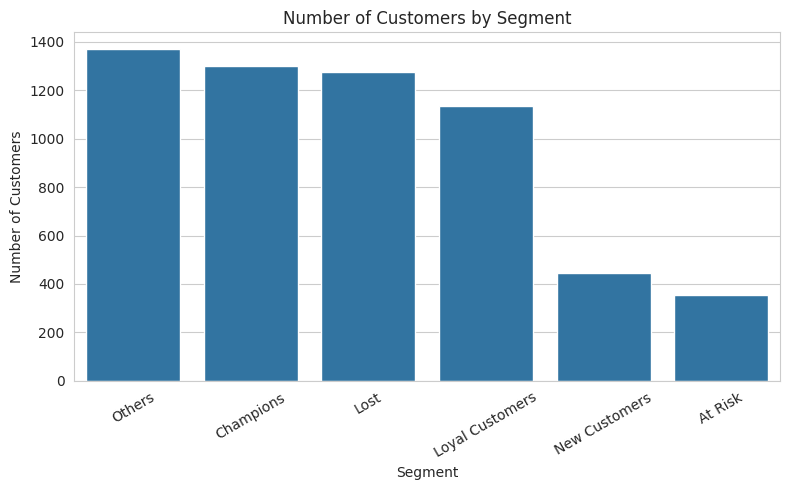

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')

# ===== จำนวนลูกค้าต่อ Segment =====
plt.figure(figsize=(8, 5))
order = rfm['Segment'].value_counts().index
sns.countplot(data=rfm, x='Segment', order=order)
plt.title('Number of Customers by Segment')
plt.xlabel('Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

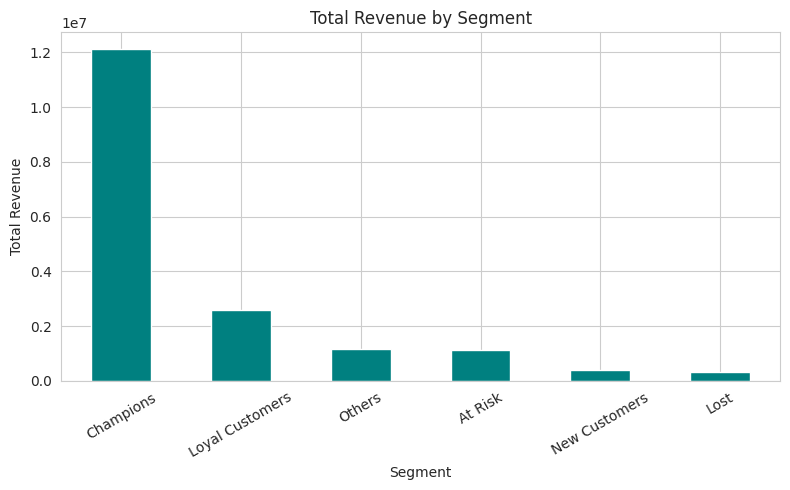

In [ ]:
# ===== Total Revenue ต่อ Segment =====
plt.figure(figsize=(8, 5))
revenue_by_segment = rfm.groupby('Segment')['Monetary'].sum().sort_values(ascending=False)
revenue_by_segment.plot(kind='bar', color='teal')
plt.title('Total Revenue by Segment')
plt.xlabel('Segment')
plt.ylabel('Total Revenue')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

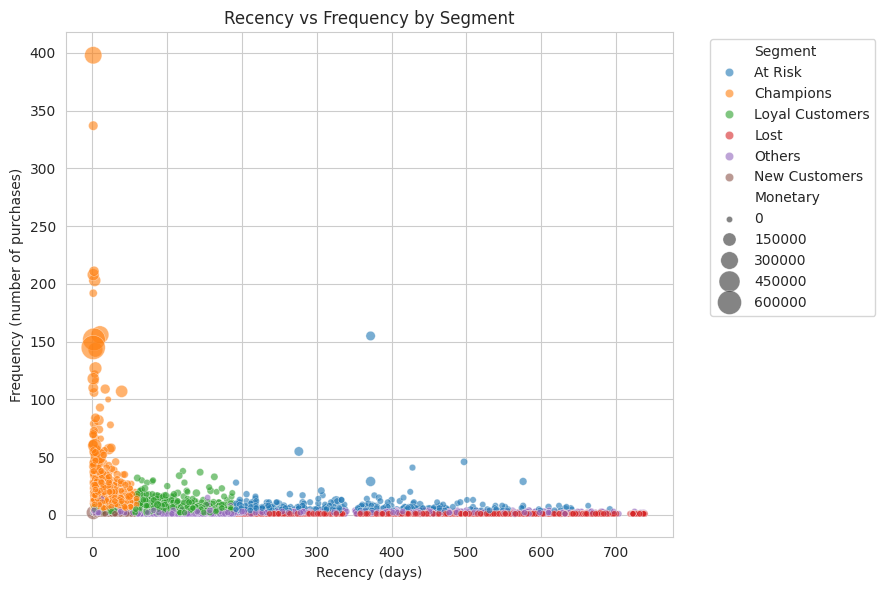

In [ ]:
# ===== Scatter Plot Recency vs Frequency แยกสีตาม Segment =====
plt.figure(figsize=(9, 6))
sns.scatterplot(data=rfm, x='Recency', y='Frequency', hue='Segment', size='Monetary',
                 sizes=(20, 300), alpha=0.6)
plt.title('Recency vs Frequency by Segment')
plt.xlabel('Recency (days)')
plt.ylabel('Frequency (number of purchases)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
import datetime as dt

# ===== 1. Data Cleaning =====
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], format='mixed', dayfirst=True)
df_clean = df.dropna(subset=['Customer ID']).copy()
df_clean = df_clean[~df_clean['Invoice'].astype(str).str.startswith('C')]
df_clean['TotalPrice'] = df_clean['Quantity'] * df_clean['Price']
df_clean['Customer ID'] = df_clean['Customer ID'].astype(int)
print("Cleaned shape:", df_clean.shape)

# ===== 2. RFM Calculation =====
reference_date = df_clean['InvoiceDate'].max() + dt.timedelta(days=1)
rfm = df_clean.groupby('Customer ID').agg(
    Recency=('InvoiceDate', lambda x: (reference_date - x.max()).days),
    Frequency=('Invoice', 'nunique'),
    Monetary=('TotalPrice', 'sum')
).reset_index()
print("RFM shape:", rfm.shape)

# ===== 3. RFM Score =====
rfm['R_Score'] = pd.qcut(rfm['Recency'], 5, labels=[5, 4, 3, 2, 1])
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5])
rfm['M_Score'] = pd.qcut(rfm['Monetary'], 5, labels=[1, 2, 3, 4, 5])
rfm['RFM_Score'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)

# ===== 4. Segment =====
def rfm_segment(row):
    r, f, m = int(row['R_Score']), int(row['F_Score']), int(row['M_Score'])
    if r >= 4 and f >= 4 and m >= 4:
        return 'Champions'
    elif r >= 3 and f >= 3 and m >= 3:
        return 'Loyal Customers'
    elif r >= 4 and f <= 2:
        return 'New Customers'
    elif r <= 2 and f >= 4:
        return 'At Risk'
    elif r <= 2 and f <= 2 and m <= 2:
        return 'Lost'
    else:
        return 'Others'

rfm['Segment'] = rfm.apply(rfm_segment, axis=1)

print("\nพร้อมแล้ว! ตัวอย่างข้อมูล:")
rfm.head()

Cleaned shape: (805620, 9)
RFM shape: (5881, 4)

พร้อมแล้ว! ตัวอย่างข้อมูล:


,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346,326,12,77556.46,2,5,5,255,At Risk
1,12347,2,8,5633.32,5,4,5,545,Champions
2,12348,75,5,2019.40,3,4,4,344,Loyal Customers
3,12349,19,4,4428.69,5,3,5,535,Loyal Customers
4,12350,310,1,334.40,2,1,2,212,Lost


**K-Means Clustering**


ขั้น 1: Scale ข้อมูลด้วย StandardScaler

In [ ]:
from sklearn.preprocessing import StandardScaler

# เลือกเฉพาะ 3 คอลัมน์ที่จะใช้ clustering
rfm_features = rfm[['Recency', 'Frequency', 'Monetary']]

# Scale ให้ทุกคอลัมน์อยู่ในสเกลเดียวกัน (mean=0, std=1)
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_features)

print(rfm_scaled[:5])  # ดูตัวอย่าง 5 แถวแรกหลัง scale

[[ 0.59459773  0.43904886  5.05939124]
 [-0.95226413  0.13163494  0.17757858]
 [-0.60374279 -0.0989255  -0.06771773]
 [-0.87110163 -0.17577897  0.09581382]
 [ 0.51820949 -0.40633941 -0.1820878 ]]


ขั้น 2: หาค่า K ที่เหมาะสมด้วย Elbow Method

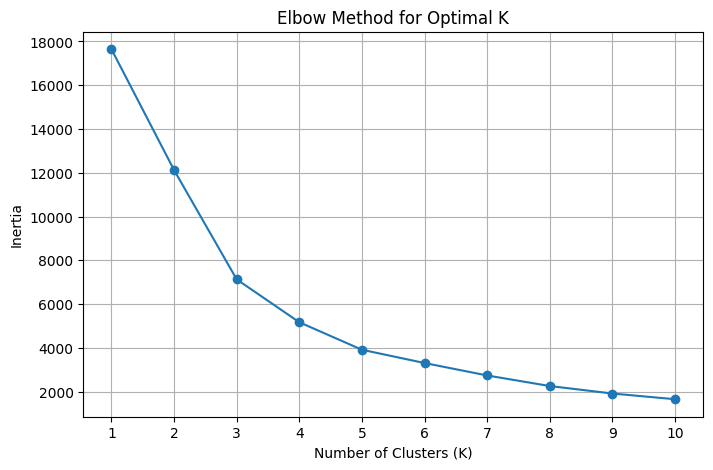

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

# Plot กราฟ Elbow
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia, marker='o')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(k_range)
plt.grid(True)
plt.show()

K=2: Silhouette Score = 0.9164
K=3: Silhouette Score = 0.5804
K=4: Silhouette Score = 0.5906
K=5: Silhouette Score = 0.6004
K=6: Silhouette Score = 0.5512
K=7: Silhouette Score = 0.5490
K=8: Silhouette Score = 0.5418
K=9: Silhouette Score = 0.5354
K=10: Silhouette Score = 0.5036


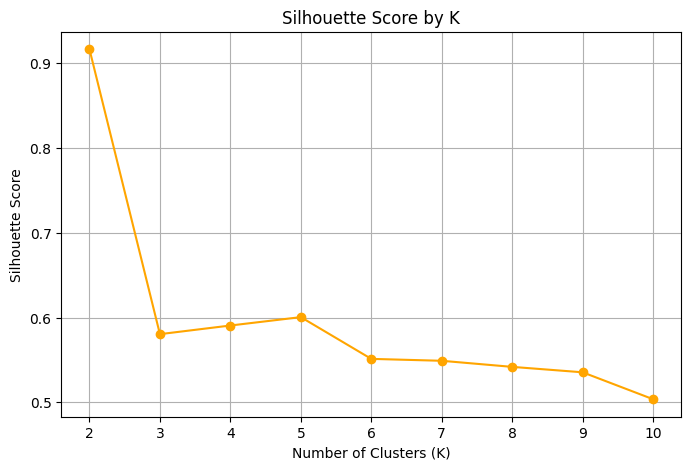

In [ ]:
from sklearn.metrics import silhouette_score

silhouette_scores = []
k_range_sil = range(2, 11)  # Silhouette ใช้กับ K=1 ไม่ได้ ต้องเริ่มจาก 2

for k in k_range_sil:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(rfm_scaled)
    score = silhouette_score(rfm_scaled, labels)
    silhouette_scores.append(score)
    print(f"K={k}: Silhouette Score = {score:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(k_range_sil, silhouette_scores, marker='o', color='orange')
plt.title('Silhouette Score by K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(k_range_sil)
plt.grid(True)
plt.show()

In [ ]:
kmeans_k2 = KMeans(n_clusters=2, random_state=42, n_init=10)
labels_k2 = kmeans_k2.fit_predict(rfm_scaled)
rfm['temp_cluster_k2'] = labels_k2
print(rfm['temp_cluster_k2'].value_counts())

temp_cluster_k2
0    5859
1      22
Name: count, dtype: int64


ขั้นต่อไป: รัน K-Means จริงด้วย K=5

In [ ]:
# รัน K-Means จริงด้วย K=5
kmeans_final = KMeans(n_clusters=5, random_state=42, n_init=10)
rfm['Cluster'] = kmeans_final.fit_predict(rfm_scaled)

# ลบคอลัมน์ทดลองที่ใช้เช็ค K=2 ทิ้ง (ไม่ใช้แล้ว)
rfm = rfm.drop(columns=['temp_cluster_k2'])

# เช็คจำนวนลูกค้าต่อ cluster
print(rfm['Cluster'].value_counts().sort_index())

# ดูค่าเฉลี่ย R, F, M ของแต่ละ cluster เพื่อเตรียมตีความ
cluster_summary = rfm.groupby('Cluster').agg(
    Customer_Count=('Customer ID', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean')
).round(1)

cluster_summary

Cluster
0     383
1    1918
2      24
3       4
4    3552
Name: count, dtype: int64


,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
0,383,28.1,28.5,13935.2
1,1918,471.5,2.2,755.1
2,24,22.5,119.8,100927.0
3,4,3.5,212.8,436835.8
4,3552,75.7,5.1,1911.2


ขั้นต่อไป: เทียบ Cluster กับ RFM Segment เดิม

In [ ]:
comparison = pd.crosstab(rfm['Segment'], rfm['Cluster'])
comparison

Cluster,0,1,2,3,4
Segment,,,,,
At Risk,9,221,1,0,123
Champions,342,0,22,4,932
Lost,0,1126,0,0,151
Loyal Customers,32,0,0,0,1103
New Customers,0,0,1,0,443
Others,0,571,0,0,800


Scatter Plot: Recency vs Frequency แยกสีตาม Cluster

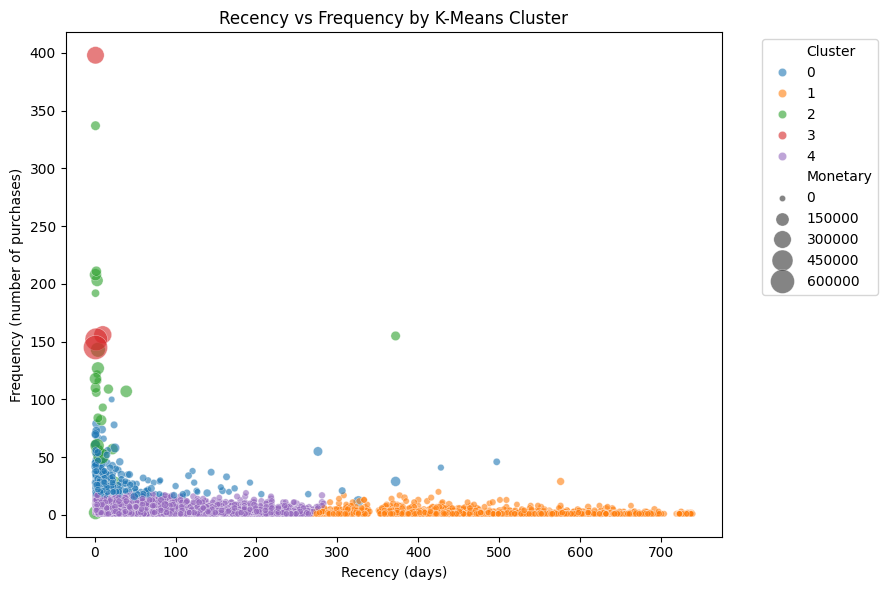

In [ ]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=rfm, x='Recency', y='Frequency', hue='Cluster', palette='tab10',
                 size='Monetary', sizes=(20, 300), alpha=0.6)
plt.title('Recency vs Frequency by K-Means Cluster')
plt.xlabel('Recency (days)')
plt.ylabel('Frequency (number of purchases)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

/tmp/ipykernel_3191/795923241.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=rfm, x='Cluster', order=cluster_order, palette='tab10')


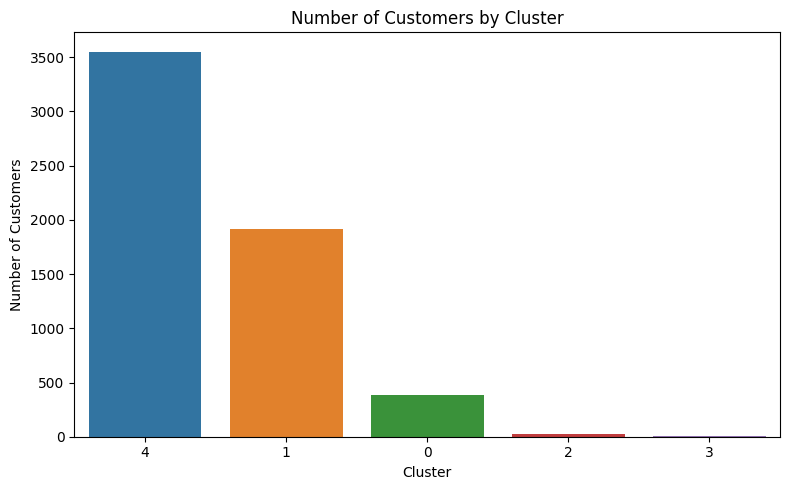

In [ ]:
plt.figure(figsize=(8, 5))
cluster_order = rfm['Cluster'].value_counts().index
sns.countplot(data=rfm, x='Cluster', order=cluster_order, palette='tab10')
plt.title('Number of Customers by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

## Summary & Business Insights

### Data Overview
- Analyzed 805,620 valid transactions from 5,881 unique customers (Dec 2009 – Dec 2011)
- Removed 243,007 rows with missing Customer ID and 18,744 cancelled orders before analysis

### RFM Segmentation
- Champions (22% of customers) generate 68% of total revenue — a clear Pareto pattern
- At Risk customers (6%) represent high-value customers who haven't purchased recently — a priority for retention campaigns

### K-Means Clustering (K=5, validated via Elbow Method + Silhouette Score)
- K-Means revealed a more precise VIP segment than RFM Score: only 28 customers (0.5%) show true wholesale-level behavior (Cluster 2 & 3), while 932 of the 1,300 "Champions" from RFM Score behave like average customers
- Recommendation: use K-Means clusters for precision targeting (VIP account management), and RFM Score for broad-based marketing communication

### Next Steps
- Build an interactive dashboard to visualize segments for business stakeholders
- Consider re-defining RFM Score thresholds using K-Means cluster boundaries for better alignment

In [ ]:
# เพิ่มชื่อ cluster ให้อ่านง่ายขึ้น (แทนเลข 0-4 ที่ไม่มีความหมายในตัวเอง)
cluster_names = {
    3: 'Super VIP',
    2: 'VIP',
    0: 'Loyal',
    4: 'Regular',
    1: 'Dormant'
}
rfm['Cluster_Name'] = rfm['Cluster'].map(cluster_names)

# Export เป็น CSV ไปเก็บใน Google Drive
rfm.to_csv('/content/drive/MyDrive/data-portfolio-project/rfm_final.csv', index=False)
print("Exported! Shape:", rfm.shape)

Exported! Shape: (5881, 11)
